<a href="https://colab.research.google.com/github/cdokku-tech/MAT422/blob/main/MAT422_Section_3_3_Optimization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MAT 422 — Section 3.3: Unconstrained Optimization

**Student:** Charan Sriraj Dokku

**Course:** MAT 422 — Mathematical Methods in Data Science

This notebook demonstrates the major ideas of Section 3.3 with short explanations, worked examples, and Python code:

| Subsection | Concepts demonstrated |
|---|---|
| **3.3.1** Necessary and sufficient conditions of local minimizers | gradient, Hessian, first-order necessary condition (FONC), second-order necessary condition (SONC), second-order sufficient condition (SOSC), classifying critical points, a case where the tests are inconclusive |
| **3.3.2** Convexity and global minimizers | convex sets and functions, first-order and second-order characterizations of convexity, "local = global" for convex functions, quadratic functions and least squares |
| **3.3.3** Gradient descent | the descent direction, steepest descent, fixed step size and its limits, $L$-smoothness and the $1/L$ step, convergence rate and condition number, backtracking line search, application to least squares |

Every claim is checked numerically or symbolically so the theory and the computation support each other.

In [ ]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

np.set_printoptions(precision=5, suppress=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

---
## 3.3.1 Necessary and sufficient conditions of local minimizers

Let $f:\mathbb{R}^d\to\mathbb{R}$. A point $x^*$ is a **local minimizer** if there is $\delta>0$ such that $f(x)\ge f(x^*)$ for all $\|x-x^*\|<\delta$. It is a **global minimizer** if $f(x)\ge f(x^*)$ for all $x$.

**Gradient and Hessian.** For a twice continuously differentiable $f$,
$$\nabla f(x)=\Big(\tfrac{\partial f}{\partial x_1},\dots,\tfrac{\partial f}{\partial x_d}\Big)^T,\qquad \mathbf{H}_f(x)=\Big[\tfrac{\partial^2 f}{\partial x_i\partial x_j}\Big]_{i,j}.$$

**Taylor expansion** (the reason everything below works):
$$f(x^*+\alpha v)=f(x^*)+\alpha\,\nabla f(x^*)^T v+\tfrac{\alpha^2}{2}\,v^T\mathbf{H}_f(x^*)\,v+o(\alpha^2).$$

**Descent direction.** $v$ is a descent direction at $x$ if $\nabla f(x)^T v<0$; then $f(x+\alpha v)<f(x)$ for small $\alpha>0$.

**Theorems.**
- **FONC:** if $x^*$ is a local minimizer, then $\nabla f(x^*)=0$.  *(Otherwise $v=-\nabla f(x^*)$ is a descent direction.)*
- **SONC:** if $x^*$ is a local minimizer, then also $\mathbf{H}_f(x^*)\succeq 0$ (positive semidefinite).
- **SOSC:** if $\nabla f(x^*)=0$ **and** $\mathbf{H}_f(x^*)\succ 0$ (positive definite), then $x^*$ is a strict local minimizer.

So a critical point with a positive definite Hessian is a local min; with a negative definite Hessian a local max; with eigenvalues of both signs a **saddle point**; and if some eigenvalue is $0$ the second-order test may be **inconclusive**.

### Example 1: A function of one variable

$f(x)=x^4-4x^3+4x^2 = x^2(x-2)^2$. We find critical points symbolically and apply the second-derivative test.

In [ ]:
x = sp.symbols('x', real=True)
f1 = x**4 - 4*x**3 + 4*x**2
df1, d2f1 = sp.diff(f1, x), sp.diff(f1, x, 2)
crit = sp.solve(sp.Eq(df1, 0), x)
print("f'(x)  =", sp.factor(df1))
print("f''(x) =", sp.expand(d2f1))
for c in crit:
    s = d2f1.subs(x, c)
    kind = "local MIN (SOSC holds)" if s > 0 else ("local MAX" if s < 0 else "inconclusive")
    print(f"x* = {c}:  f = {f1.subs(x, c)},  f'' = {s}  ->  {kind}")

f'(x)  = 4*x*(x - 2)*(x - 1)
f''(x) = 12*x**2 - 24*x + 8
x* = 0:  f = 0,  f'' = 8  ->  local MIN (SOSC holds)
x* = 1:  f = 1,  f'' = -4  ->  local MAX
x* = 2:  f = 0,  f'' = 8  ->  local MIN (SOSC holds)


SymPy factors $f'(x)=4x(x-1)(x-2)$, giving three critical points. Two pass the second-derivative test as minimizers and one fails it. The plot shows where they sit on the graph.

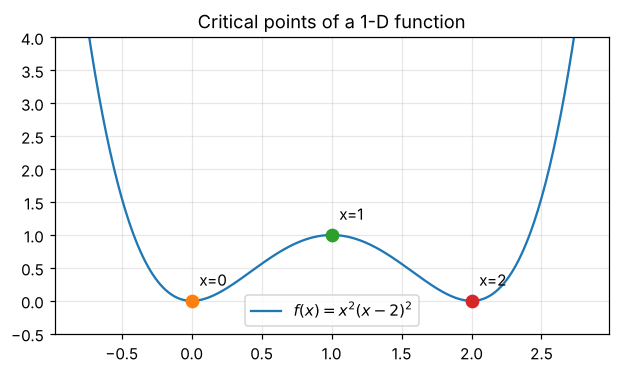

In [ ]:
f1_np = sp.lambdify(x, f1, "numpy")
xs = np.linspace(-0.8, 2.8, 400)
plt.figure(figsize=(6.5, 3.5))
plt.plot(xs, f1_np(xs), label=r"$f(x)=x^2(x-2)^2$")
for c in crit:
    c = float(c)
    plt.plot(c, f1_np(c), "o", ms=8)
    plt.annotate(f"x={c:g}", (c, f1_np(c)), textcoords="offset points", xytext=(5, 10))
plt.ylim(-0.5, 4); plt.legend(); plt.title("Critical points of a 1-D function")
plt.show()

Both $x=0$ and $x=2$ satisfy FONC and SOSC, so they are strict local minimizers (and global, since $f\ge 0=f(0)=f(2)$). The point $x=1$ satisfies FONC but $f''(1)<0$, so it violates SONC and is a local maximum. **FONC alone does not identify minimizers.**

### Example 2: Classifying critical points in two variables

$f(x,y)=x^3-3x+y^2$. We compute the gradient and Hessian with SymPy, solve $\nabla f=0$, and inspect Hessian eigenvalues.

In [ ]:
X, Y = sp.symbols('x y', real=True)
f2 = X**3 - 3*X + Y**2
grad2 = sp.Matrix([sp.diff(f2, v) for v in (X, Y)])
H2 = sp.hessian(f2, (X, Y))
print("grad f =", list(grad2))
print("Hessian =", H2.tolist())

def classify(H):
    ev = np.linalg.eigvalsh(np.array(H, dtype=float))
    if np.all(ev > 0):   return ev, "positive definite -> strict local MIN"
    if np.all(ev < 0):   return ev, "negative definite -> strict local MAX"
    if ev.min() < 0 < ev.max(): return ev, "indefinite -> SADDLE point"
    return ev, "semidefinite -> second-order test INCONCLUSIVE"

pts2 = sp.solve(list(grad2), (X, Y), dict=True)
for p in pts2:
    ev, kind = classify(H2.subs(p))
    print(f"({p[X]}, {p[Y]}): f = {f2.subs(p)}, eigenvalues = {ev} -> {kind}")

grad f = [3*x**2 - 3, 2*y]
Hessian = [[6*x, 0], [0, 2]]
(-1, 0): f = 2, eigenvalues = [-6.  2.] -> indefinite -> SADDLE point
(1, 0): f = -2, eigenvalues = [2. 6.] -> positive definite -> strict local MIN


Only $(1,0)$ has all-positive Hessian eigenvalues; at $(-1,0)$ they have opposite signs. The surface and contour plots below make the difference visible.

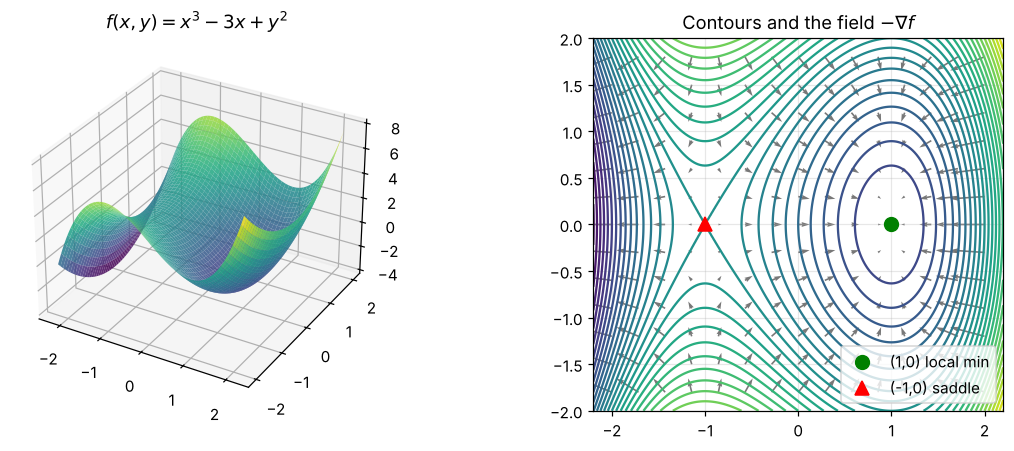

In [ ]:
f2_np = sp.lambdify((X, Y), f2, "numpy")
gx, gy = np.meshgrid(np.linspace(-2.2, 2.2, 200), np.linspace(-2, 2, 200))
Z = f2_np(gx, gy)

fig = plt.figure(figsize=(11, 4.2))
ax = fig.add_subplot(1, 2, 1, projection="3d")
ax.plot_surface(gx, gy, Z, cmap="viridis", alpha=0.85, linewidth=0)
ax.set_title(r"$f(x,y)=x^3-3x+y^2$")
ax2 = fig.add_subplot(1, 2, 2)
cs = ax2.contour(gx, gy, Z, levels=30, cmap="viridis")
ax2.plot(1, 0, "go", ms=9, label="(1,0) local min")
ax2.plot(-1, 0, "r^", ms=9, label="(-1,0) saddle")
gxs, gys = np.meshgrid(np.linspace(-2, 2, 15), np.linspace(-1.8, 1.8, 13))
ax2.quiver(gxs, gys, -(3*gxs**2 - 3), -2*gys, color="dimgray", alpha=0.9, width=0.004)  # -grad = descent directions
ax2.set_title("Contours and the field $-\\nabla f$"); ax2.legend(loc="lower right"); ax2.set_aspect("equal")
plt.tight_layout(); plt.show()

The arrows show $-\nabla f$, the steepest descent direction. They flow **into** the local minimizer $(1,0)$, while near the saddle $(-1,0)$ they flow in along the $y$-direction and out along the $x$-direction.

Note that $(1,0)$ is a local but **not** global minimizer: $f(x,0)=x^3-3x\to-\infty$ as $x\to-\infty$. Local conditions only describe a neighborhood.

### Numerical check of SOSC via Taylor expansion

If $\nabla f(x^*)=0$ and $\mathbf{H}\succ0$, then $f(x^*+\alpha v)-f(x^*)\approx\frac{\alpha^2}{2}v^T\mathbf{H}v>0$ for every direction $v$. We test 2000 random directions around both critical points.

In [ ]:
rng = np.random.default_rng(0)
V = rng.normal(size=(2000, 2)); V /= np.linalg.norm(V, axis=1, keepdims=True)
alpha = 1e-2
for p, name in [((1.0, 0.0), "(1,0)"), ((-1.0, 0.0), "(-1,0)")]:
    diff = f2_np(p[0] + alpha*V[:, 0], p[1] + alpha*V[:, 1]) - f2_np(*p)
    H = np.array(H2.subs({X: p[0], Y: p[1]}), dtype=float)
    quad = 0.5 * alpha**2 * np.einsum("ij,jk,ik->i", V, H, V)
    print(f"{name}: fraction of directions with f increase = {np.mean(diff > 0):.3f}; "
          f"max |actual - quadratic model| = {np.max(np.abs(diff - quad)):.2e}")

(1,0): fraction of directions with f increase = 1.000; max |actual - quadratic model| = 1.00e-06
(-1,0): fraction of directions with f increase = 0.316; max |actual - quadratic model| = 1.00e-06


At $(1,0)$ every direction increases $f$ (strict local min). At the saddle only some directions do. The tiny model error confirms that the second-order Taylor term governs the local behavior.

### Example 3: When the second-order test is inconclusive

Consider $g_1(x,y)=x^4+y^4$, $g_2(x,y)=-x^4-y^4$, $g_3(x,y)=x^4-y^4$. At the origin all three have $\nabla g=0$ **and** $\mathbf{H}=0$, so FONC and SONC hold for all of them, yet they are a min, a max and a saddle respectively. This shows SONC is necessary but **not sufficient**, and SOSC is sufficient but **not necessary** ($g_1$ has a strict minimum with a singular Hessian).

x^4+y^4    grad(0)=[0, 0]  Hessian(0)=[[0, 0], [0, 0]]
-x^4-y^4   grad(0)=[0, 0]  Hessian(0)=[[0, 0], [0, 0]]
x^4-y^4    grad(0)=[0, 0]  Hessian(0)=[[0, 0], [0, 0]]


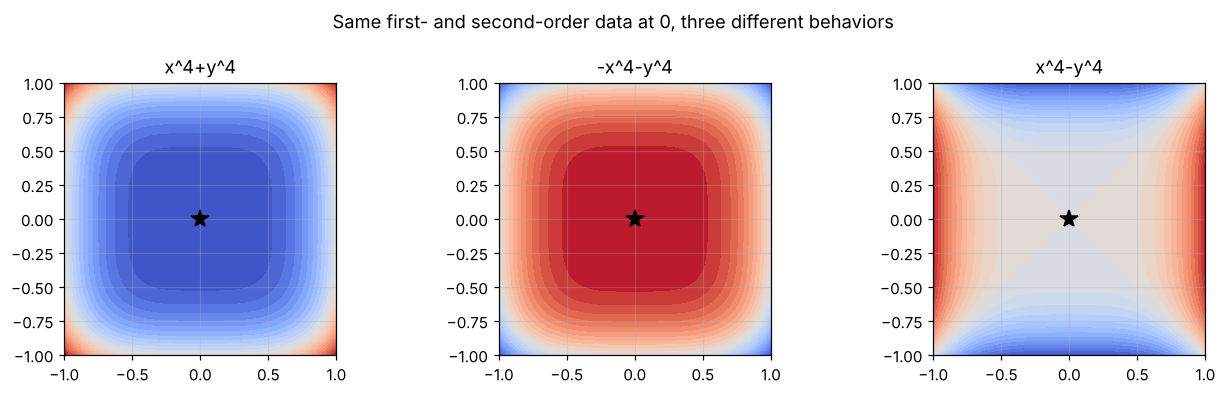

In [ ]:
gs = {"x^4+y^4": X**4 + Y**4, "-x^4-y^4": -X**4 - Y**4, "x^4-y^4": X**4 - Y**4}
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
gx, gy = np.meshgrid(np.linspace(-1, 1, 150), np.linspace(-1, 1, 150))
for ax, (name, g) in zip(axes, gs.items()):
    grad = [sp.diff(g, v).subs({X: 0, Y: 0}) for v in (X, Y)]
    H = sp.hessian(g, (X, Y)).subs({X: 0, Y: 0})
    print(f"{name:10s} grad(0)={grad}  Hessian(0)={H.tolist()}")
    ax.contourf(gx, gy, sp.lambdify((X, Y), g, "numpy")(gx, gy), levels=25, cmap="coolwarm")
    ax.plot(0, 0, "k*", ms=12); ax.set_title(name); ax.set_aspect("equal")
plt.suptitle("Same first- and second-order data at 0, three different behaviors"); plt.tight_layout(); plt.show()

All three print the same zero gradient and zero Hessian at the origin, yet the colors show a bowl, a dome and a saddle. Fourth-order terms decide the behavior, which is why a second-order test cannot.

---
## 3.3.2 Convexity and global minimizers

**Convex set.** $D\subseteq\mathbb{R}^d$ is convex if for all $x,y\in D$ and $\alpha\in[0,1]$, $(1-\alpha)x+\alpha y\in D$.

**Convex function.** $f$ is convex on a convex set $D$ if
$$f\big((1-\alpha)x+\alpha y\big)\le(1-\alpha)f(x)+\alpha f(y)\quad\forall x,y\in D,\ \alpha\in[0,1],$$
i.e. every chord lies on or above the graph.

**Characterizations** (for differentiable $f$):
- **First-order:** $f$ is convex $\iff f(y)\ge f(x)+\nabla f(x)^T(y-x)$ for all $x,y$ (the tangent plane is a global under-estimator).
- **Second-order:** for twice differentiable $f$, $f$ is convex $\iff \mathbf{H}_f(x)\succeq0$ for all $x$.

**Key theorem.** If $f$ is convex, then **every local minimizer is a global minimizer**, and for differentiable convex $f$, $\nabla f(x^*)=0 \iff x^*$ is a global minimizer. (Proof: the first-order condition gives $f(y)\ge f(x^*)+0$ for all $y$.) If $f$ is strictly convex, the global minimizer, if it exists, is unique.

### Convex sets: a visual check
We sample pairs of points in each set and test whether the segment between them stays inside.

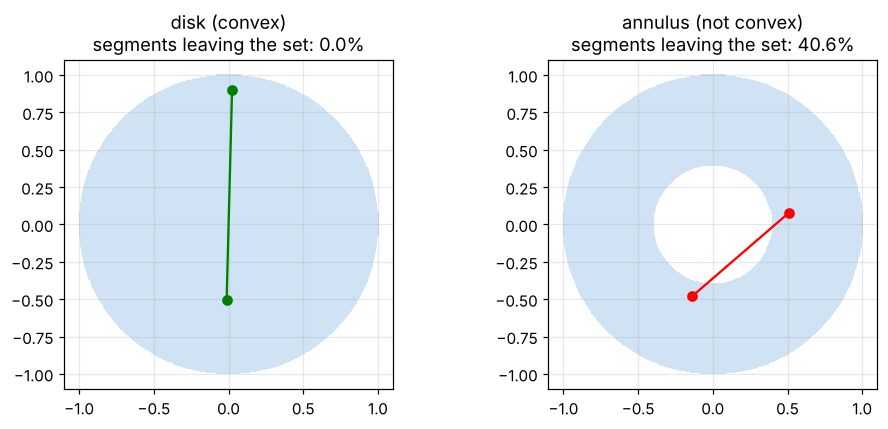

In [ ]:
def in_disk(p):    return p[..., 0]**2 + p[..., 1]**2 <= 1
def in_annulus(p): r2 = p[..., 0]**2 + p[..., 1]**2; return (r2 >= 0.4**2) & (r2 <= 1)

def convexity_violation_rate(member, trials=4000, seed=1):
    rng = np.random.default_rng(seed)
    P = rng.uniform(-1, 1, size=(trials * 6, 2)); P = P[member(P)]
    a, b = P[: len(P)//2], P[len(P)//2 : 2*(len(P)//2)]
    t = np.linspace(0, 1, 25)[:, None, None]
    seg = (1 - t) * a + t * b
    return np.mean(~np.all(member(seg), axis=0)), a, b

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, (name, m) in zip(axes, [("disk (convex)", in_disk), ("annulus (not convex)", in_annulus)]):
    rate, a, b = convexity_violation_rate(m)
    gx, gy = np.meshgrid(np.linspace(-1.1, 1.1, 300), np.linspace(-1.1, 1.1, 300))
    ax.contourf(gx, gy, m(np.stack([gx, gy], -1)), levels=[0.5, 1.5], colors=["#cfe3f5"])
    bad = None
    for i in range(len(a)):
        seg = np.linspace(a[i], b[i], 25)
        if not np.all(m(seg)): bad = (a[i], b[i]); break
    if bad is None: bad = (a[0], b[0])
    ax.plot(*np.array(bad).T, "r-o" if m is in_annulus else "g-o")
    ax.set_title(f"{name}\nsegments leaving the set: {rate:.1%}"); ax.set_aspect("equal")
plt.tight_layout(); plt.show()

No segment between two points of the disk leaves the disk, while a sizable fraction of segments in the annulus cross the hole (one is drawn in red). The disk is convex; the annulus is not.

### Testing convexity of functions: definition, first-order and second-order conditions

We check the three equivalent conditions numerically for a convex function $f(x)=e^{x}+x^2$ and a non-convex function $g(x)=\sin x+0.1x^2$.

In [ ]:
fx  = lambda t: np.exp(t) + t**2;        dfx = lambda t: np.exp(t) + 2*t;    d2fx = lambda t: np.exp(t) + 2
gx_ = lambda t: np.sin(t) + 0.1*t**2;    dgx = lambda t: np.cos(t) + 0.2*t;  d2gx = lambda t: -np.sin(t) + 0.2

rng = np.random.default_rng(2)
a, b = rng.uniform(-4, 4, 20000), rng.uniform(-4, 4, 20000); al = rng.uniform(0, 1, 20000)
for name, F, dF, d2F in [("e^x + x^2", fx, dfx, d2fx), ("sin x + 0.1x^2", gx_, dgx, d2gx)]:
    chord = np.mean(F((1-al)*a + al*b) <= (1-al)*F(a) + al*F(b) + 1e-12)
    tang  = np.mean(F(b) >= F(a) + dF(a)*(b - a) - 1e-12)
    hess  = np.min(d2F(np.linspace(-4, 4, 2001)))
    print(f"{name:16s} chord test holds {chord:.1%} | tangent test holds {tang:.1%} | min f'' = {hess:+.3f}")

e^x + x^2        chord test holds 100.0% | tangent test holds 100.0% | min f'' = +2.018
sin x + 0.1x^2   chord test holds 58.4% | tangent test holds 58.4% | min f'' = -0.800


All three tests pass for $e^x+x^2$, whose second derivative never drops below 2. For $\sin x+0.1x^2$ the chord and tangent tests fail for many random pairs and $g''$ reaches $-0.8$, so it is not convex. The plot below shows both tests geometrically.

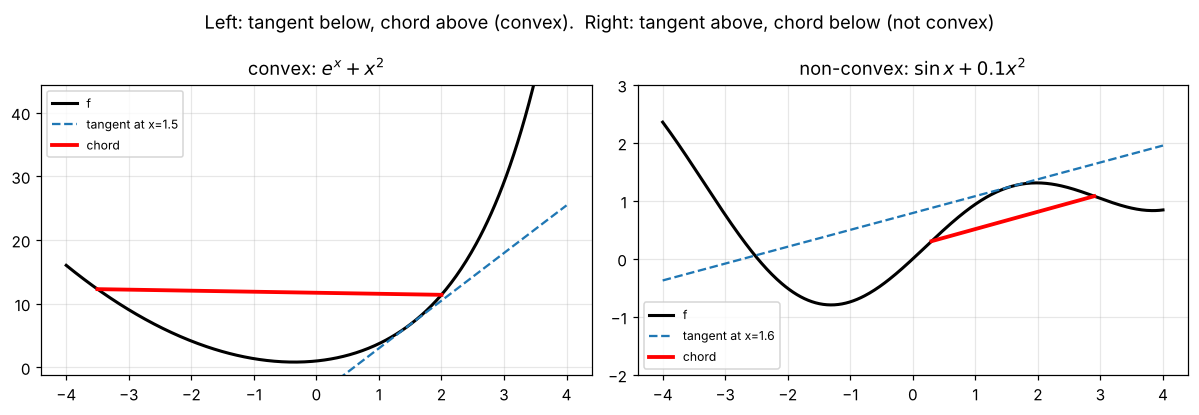

In [ ]:
ts = np.linspace(-4, 4, 400)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
panels = [("convex: $e^x+x^2$", fx, dfx, (-3.5, 2.0), 1.5),
          ("non-convex: $\\sin x+0.1x^2$", gx_, dgx, (0.3, 2.9), 1.6)]   # chord over the region where g'' < 0
for ax, (name, F, dF, (p, q), x0) in zip(axes, panels):
    ax.plot(ts, F(ts), "k", lw=2, label="f")
    ax.plot(ts, F(x0) + dF(x0)*(ts - x0), "--", color="tab:blue", label=f"tangent at x={x0}")
    ax.plot([p, q], [F(p), F(q)], "r-", lw=2.5, label="chord")
    ax.set_ylim(F(ts).min() - 2, F(ts).max() * 0.6 + 2); ax.set_title(name); ax.legend(fontsize=8)
axes[1].set_ylim(-2, 3)
plt.suptitle("Left: tangent below, chord above (convex).  Right: tangent above, chord below (not convex)")
plt.tight_layout(); plt.show()

For the convex function every tangent line lies below the graph and every chord above it. For $\sin x+0.1x^2$ both properties fail somewhere, matching the fact that $g''(x)=-\sin x+0.2$ takes negative values.

### Local minimizers are global for convex functions (and not otherwise)

We run a local minimizer (gradient descent, developed in 3.3.3) from many starting points. For the convex function every run reaches the same value; for the non-convex function runs get stuck in different local minima.

In [ ]:
def gd_1d(df, x0, lr=0.05, iters=2000):
    x = x0
    for _ in range(iters): x -= lr * df(x)
    return x

starts = np.linspace(-15, 15, 31)
for name, F, dF in [("e^x + x^2", fx, dfx), ("sin x + 0.1x^2", gx_, dgx)]:
    ends = np.array([gd_1d(dF, s, lr=0.05 if F is gx_ else 0.01) for s in starts])
    vals = [float(v) for v in np.round(F(ends), 4)]
    print(f"{name:16s}: distinct final values = {sorted(set(vals))}")

e^x + x^2       : distinct final values = [0.8272]
sin x + 0.1x^2  : distinct final values = [-0.7946, 0.8316]


The convex function ends at one value from every start: its unique global minimum. The non-convex function ends at two different values, so some runs stop at a local minimum that is not global.

### Quadratic functions and least squares

A quadratic $q(x)=\tfrac12 x^TPx+q^Tx+r$ with symmetric $P$ has $\mathbf{H}=P$, so $q$ is convex iff $P\succeq0$. If $P\succ0$ the unique global minimizer solves $\nabla q = Px+q=0$, i.e. $x^*=-P^{-1}q$.

**Least squares** is the main example: $f(x)=\|Ax-b\|^2$ has $\nabla f=2A^T(Ax-b)$ and $\mathbf{H}=2A^TA\succeq0$, so it is convex, and the **normal equations** $A^TAx=A^Tb$ characterize all global minimizers.

In [ ]:
rng = np.random.default_rng(3)
n = 60
t = np.linspace(0, 4, n)
b = 1.5 + 0.8*t - 0.3*t**2 + rng.normal(0, 0.4, n)       # noisy data
A = np.column_stack([np.ones(n), t, t**2])               # quadratic model

H_ls = 2 * A.T @ A
print("Hessian eigenvalues of ||Ax-b||^2:", np.linalg.eigvalsh(H_ls), "-> positive definite, strictly convex")
x_star = np.linalg.solve(A.T @ A, A.T @ b)
print("normal-equation solution  x* =", x_star)
print("np.linalg.lstsq solution     =", np.linalg.lstsq(A, b, rcond=None)[0])
print("gradient at x*:", 2*A.T @ (A @ x_star - b))

# global-optimality check: no random point does better
f_ls = lambda x: np.sum((A @ x - b)**2)
trial = x_star + rng.normal(0, 1, size=(5000, 3))
print("any random point with smaller loss?", any(f_ls(z) < f_ls(x_star) for z in trial))

Hessian eigenvalues of ||Ax-b||^2: [   6.36525   81.46475 6978.0863 ] -> positive definite, strictly convex
normal-equation solution  x* = [ 1.39418  0.94266 -0.33437]
np.linalg.lstsq solution     = [ 1.39418  0.94266 -0.33437]
gradient at x*: [-0.  0. -0.]
any random point with smaller loss? False


The gradient at $x^*$ is zero to machine precision, NumPy's solver agrees with the normal equations, and none of 5,000 random nearby points has a smaller loss, exactly as convexity predicts. The plot shows the fitted curve.

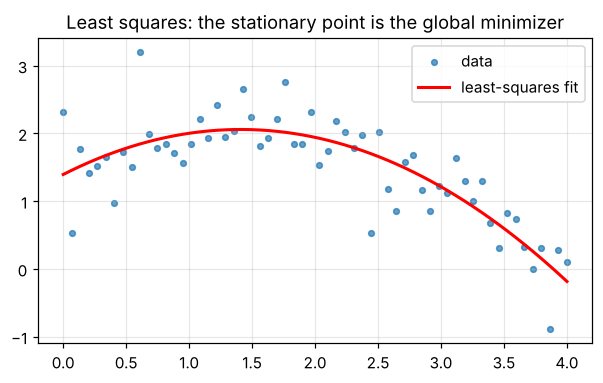

In [ ]:
plt.figure(figsize=(6.5, 3.6))
plt.scatter(t, b, s=14, alpha=0.7, label="data")
plt.plot(t, A @ x_star, "r", lw=2, label="least-squares fit")
plt.title("Least squares: the stationary point is the global minimizer"); plt.legend(); plt.show()

---
## 3.3.3 Gradient descent

**Steepest descent.** Among unit vectors $v$, the directional derivative $\nabla f(x)^Tv$ is smallest at $v=-\nabla f(x)/\|\nabla f(x)\|$ (Cauchy–Schwarz). Gradient descent repeatedly steps in that direction:
$$x^{k+1}=x^k-\alpha_k\nabla f(x^k).$$

**Smoothness and step size.** $f$ is **$L$-smooth** if $\|\nabla f(x)-\nabla f(y)\|\le L\|x-y\|$; for $C^2$ functions this means $-L I\preceq\mathbf{H}_f\preceq LI$. Then the *descent lemma* gives
$$f\big(x-\tfrac1L\nabla f(x)\big)\le f(x)-\tfrac{1}{2L}\|\nabla f(x)\|^2,$$
so with $\alpha=1/L$ every step decreases $f$ and $\nabla f(x^k)\to0$ (convergence to a stationary point).

**Strongly convex case.** If additionally $\mathbf{H}_f\succeq m I$ with $m>0$, then with $\alpha=1/L$
$$f(x^k)-f(x^*)\le\Big(1-\tfrac{m}{L}\Big)^k\big(f(x^0)-f(x^*)\big),$$
**linear convergence** with rate controlled by the **condition number** $\kappa=L/m$.

For the quadratic $f(x)=\tfrac12x^TPx$, $L=\lambda_{\max}(P)$, $m=\lambda_{\min}(P)$, and gradient descent converges iff $0<\alpha<2/L$.

In [ ]:
def gradient_descent(grad, x0, step, iters=200, f=None, tol=1e-10):
    # Fixed-step gradient descent; returns array of iterates.
    xs = [np.asarray(x0, float)]
    for _ in range(iters):
        g = grad(xs[-1])
        if np.linalg.norm(g) < tol: break
        xs.append(xs[-1] - step * g)
    return np.array(xs)

def contour_path(ax, f, paths, xlim, ylim, title, levels=30):
    gx, gy = np.meshgrid(np.linspace(*xlim, 250), np.linspace(*ylim, 250))
    ax.contour(gx, gy, f(np.stack([gx, gy])), levels=levels, cmap="viridis", alpha=0.7)
    for (P, lab, c) in paths:
        ax.plot(P[:, 0], P[:, 1], "-o", ms=3, color=c, label=lab)
    ax.plot(0, 0, "k*", ms=12); ax.set_title(title); ax.legend(fontsize=8)

### Effect of the step size on a quadratic

$f(x)=\tfrac12x^TPx$ with $P=\mathrm{diag}(1,10)$, so $m=1$, $L=10$, $\kappa=10$. We try $\alpha=0.02$ (too small), $\alpha=1/L=0.1$, $\alpha=0.19$ (just under $2/L$), and $\alpha=0.21$ (just over $2/L$, diverges).

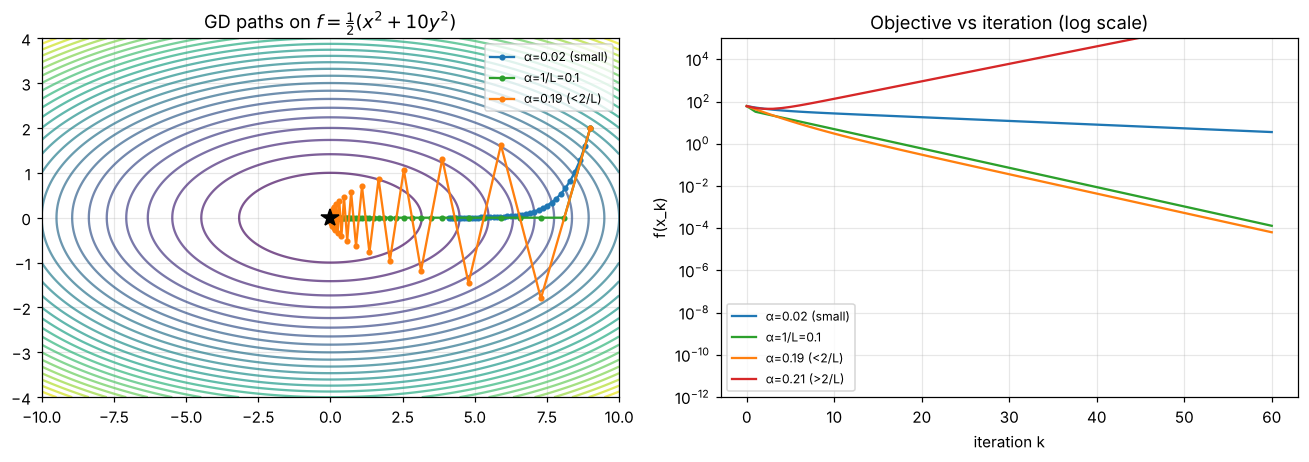

In [ ]:
P = np.diag([1.0, 10.0])
fq = lambda z: 0.5 * (P[0, 0]*z[0]**2 + P[1, 1]*z[1]**2)
gq = lambda z: P @ z
L, m = np.linalg.eigvalsh(P).max(), np.linalg.eigvalsh(P).min()
x0 = np.array([9.0, 2.0])

steps = [(0.02, "α=0.02 (small)", "tab:blue"), (1/L, "α=1/L=0.1", "tab:green"),
         (0.19, "α=0.19 (<2/L)", "tab:orange"), (0.21, "α=0.21 (>2/L)", "tab:red")]
runs = {lab: gradient_descent(gq, x0, a, iters=60) for a, lab, _ in steps}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
contour_path(axes[0], fq, [(runs[lab][:40], lab, c) for _, lab, c in steps[:3]],
             (-10, 10), (-4, 4), "GD paths on $f=\\frac{1}{2}(x^2+10y^2)$")
for a, lab, c in steps:
    vals = [fq(z) for z in runs[lab]]
    axes[1].semilogy(vals, color=c, label=lab)
axes[1].set_xlabel("iteration k"); axes[1].set_ylabel("f(x_k)"); axes[1].set_title("Objective vs iteration (log scale)")
axes[1].set_ylim(1e-12, 1e5); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

- Too small a step makes slow, steady progress.
- $\alpha=1/L$ converges quickly and monotonically.
- $\alpha$ close to $2/L$ zig-zags across the steep $y$-direction, oscillating but still converging.
- $\alpha>2/L$ makes the $y$-component grow by a factor $|1-10\alpha|>1$ each step: **divergence**.

### Verifying the theoretical rate and the role of the condition number

For $\alpha=1/L$ we compare the observed decrease of $f(x_k)-f(x^*)$ with the bound $(1-1/\kappa)^k$, for several condition numbers.

kappa=   2: iterations to reduce gap by 1e6 = 10
kappa=  10: iterations to reduce gap by 1e6 = 55
kappa=  50: iterations to reduce gap by 1e6 = 245
kappa= 200: iterations to reduce gap by 1e6 = 850


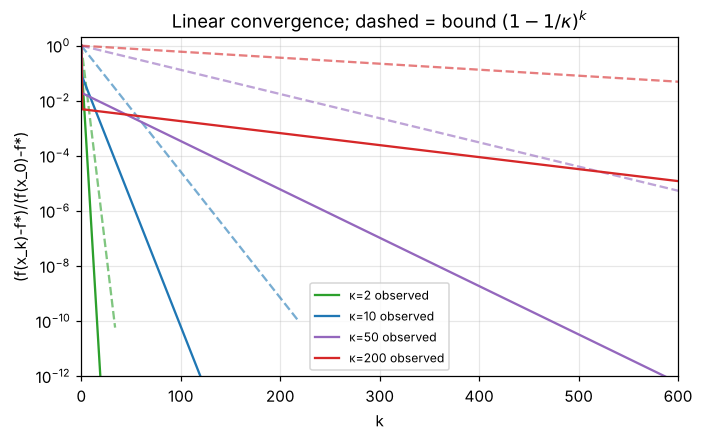

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))
for kappa, c in [(2, "tab:green"), (10, "tab:blue"), (50, "tab:purple"), (200, "tab:red")]:
    Pk = np.diag([1.0, float(kappa)])
    fk = lambda z, Pk=Pk: 0.5 * z @ Pk @ z
    path = gradient_descent(lambda z, Pk=Pk: Pk @ z, np.array([1.0, 1.0]), 1/kappa, iters=3000)
    gap = np.array([fk(z) for z in path]); k = np.arange(len(gap))
    ax.semilogy(k, gap / gap[0], color=c, label=f"κ={kappa} observed")
    ax.semilogy(k, (1 - 1/kappa)**k, "--", color=c, alpha=0.6)
    hit = np.argmax(gap/gap[0] < 1e-6) if np.any(gap/gap[0] < 1e-6) else None
    print(f"kappa={kappa:4d}: iterations to reduce gap by 1e6 = {hit}")
ax.set_xlim(0, 600); ax.set_ylim(1e-12, 2); ax.set_xlabel("k"); ax.set_ylabel("(f(x_k)-f*)/(f(x_0)-f*)")
ax.set_title("Linear convergence; dashed = bound $(1-1/\\kappa)^k$"); ax.legend(fontsize=8)
plt.show()

Every observed curve lies below its dashed bound, and the number of iterations grows roughly in proportion to $\kappa$. Ill-conditioned problems are slow for gradient descent.

### Backtracking (Armijo) line search

When $L$ is unknown, choose $\alpha_k$ adaptively: start at $\alpha=\alpha_0$ and shrink $\alpha\leftarrow\beta\alpha$ until the **sufficient-decrease condition**
$$f(x-\alpha\nabla f(x))\le f(x)-c\,\alpha\|\nabla f(x)\|^2$$
holds (we use $c=0.5$, $\beta=0.5$). We test it on the non-quadratic, non-convex **Rosenbrock function** $f(x,y)=(1-x)^2+100(y-x^2)^2$ whose global minimizer is $(1,1)$.

iterations: 468, final point: [1. 1.], f = 1.17e-12
Hessian eigenvalues at (1,1): [   0.39936 1001.60064] -> SOSC holds


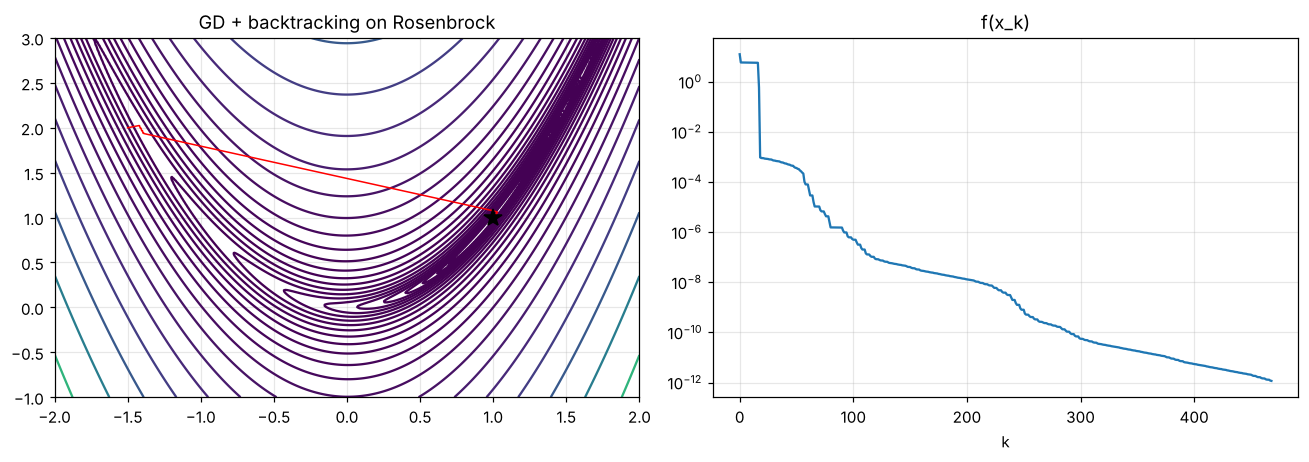

In [ ]:
def gd_backtracking(f, grad, x0, a0=1.0, beta=0.5, c=0.5, iters=20000, tol=1e-6):
    x = np.asarray(x0, float); xs = [x.copy()]
    for _ in range(iters):
        g = grad(x)
        if np.linalg.norm(g) < tol: break
        a = a0
        while f(x - a*g) > f(x) - c*a*(g @ g):
            a *= beta
        x = x - a*g; xs.append(x.copy())
    return np.array(xs)

rosen = lambda z: (1 - z[0])**2 + 100*(z[1] - z[0]**2)**2
rosen_grad = lambda z: np.array([-2*(1 - z[0]) - 400*z[0]*(z[1] - z[0]**2), 200*(z[1] - z[0]**2)])

path_r = gd_backtracking(rosen, rosen_grad, [-1.5, 2.0])
print(f"iterations: {len(path_r)-1}, final point: {path_r[-1]}, f = {rosen(path_r[-1]):.2e}")

# Confirm 3.3.1 conditions at the computed point
rosen_hess = lambda z: np.array([[2 - 400*(z[1] - 3*z[0]**2), -400*z[0]], [-400*z[0], 200.0]])
Hr = rosen_hess(np.array([1.0, 1.0]))
print("Hessian eigenvalues at (1,1):", np.linalg.eigvalsh(Hr), "-> SOSC holds")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
gx, gy = np.meshgrid(np.linspace(-2, 2, 300), np.linspace(-1, 3, 300))
axes[0].contour(gx, gy, rosen(np.stack([gx, gy])), levels=np.logspace(-1, 3.5, 25), cmap="viridis")
axes[0].plot(path_r[:, 0], path_r[:, 1], "r-", lw=1); axes[0].plot(1, 1, "k*", ms=12)
axes[0].set_title("GD + backtracking on Rosenbrock")
axes[1].semilogy([rosen(z) for z in path_r]); axes[1].set_xlabel("k"); axes[1].set_title("f(x_k)")
plt.tight_layout(); plt.show()

The iterates quickly reach the curved valley and then crawl along it. Near $(1,1)$ the Hessian has eigenvalues of very different sizes (condition number about 2500), which explains the many iterations, exactly the effect seen in the previous experiment.

### Gradient descent for least squares

Returning to the regression in 3.3.2: $f(x)=\|Ax-b\|^2$ is $L$-smooth with $L=2\lambda_{\max}(A^TA)$. Gradient descent with $\alpha=1/L$ converges to the normal-equation solution. We also see how **feature scaling** improves the condition number.

GD solution (raw features): [ 1.39418  0.94266 -0.33437]
normal equations          : [ 1.39418  0.94266 -0.33437]
condition number of A^T A: raw = 1096.3, column-scaled = 270.5


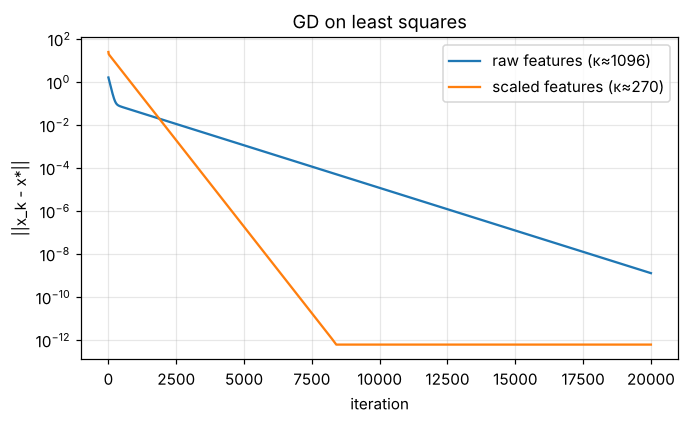

In [ ]:
def gd_lstsq(A, b, iters=20000):
    L = 2 * np.linalg.eigvalsh(A.T @ A).max()
    x = np.zeros(A.shape[1]); errs = []
    xs = np.linalg.lstsq(A, b, rcond=None)[0]
    for _ in range(iters):
        x = x - (1/L) * 2 * A.T @ (A @ x - b)
        errs.append(np.linalg.norm(x - xs))
    return x, np.array(errs), np.linalg.cond(A.T @ A)

A_scaled = A / np.linalg.norm(A, axis=0)       # normalize columns
x_raw, e_raw, k_raw = gd_lstsq(A, b)
x_sc,  e_sc,  k_sc  = gd_lstsq(A_scaled, b)

print("GD solution (raw features):", x_raw)
print("normal equations          :", x_star)
print(f"condition number of A^T A: raw = {k_raw:.1f}, column-scaled = {k_sc:.1f}")

plt.figure(figsize=(7, 3.8))
plt.semilogy(e_raw, label=f"raw features (κ≈{k_raw:.0f})")
plt.semilogy(e_sc, label=f"scaled features (κ≈{k_sc:.0f})")
plt.xlabel("iteration"); plt.ylabel("||x_k - x*||"); plt.title("GD on least squares"); plt.legend(); plt.show()

Gradient descent with $\alpha=1/L$ reaches the same coefficients as the normal equations. Scaling the columns cut the condition number of $A^TA$ from about 1100 to about 270, and the error for the scaled problem falls noticeably faster.

### My own example: training a logistic regression classifier with gradient descent

Least squares is the classic example, but most classifiers in data science are trained by minimizing a different loss. Logistic regression predicts $P(y=1\mid x)=\sigma(w^Tx)$ with $\sigma(z)=1/(1+e^{-z})$ and minimizes the average **log-loss**
$$\ell(w)=\frac1n\sum_{i=1}^n\Big[\log\big(1+e^{w^Tx_i}\big)-y_i\,w^Tx_i\Big].$$

This example uses all three subsections:
- **3.3.2:** $\nabla\ell(w)=\frac1n X^T(\sigma(Xw)-y)$ and $\mathbf H_\ell(w)=\frac1n X^T S X$ with $S=\mathrm{diag}\big(\sigma_i(1-\sigma_i)\big)$. Since $S\succeq0$, the Hessian is positive semidefinite everywhere, so $\ell$ is **convex** and any stationary point is a global minimizer. Unlike least squares there is no closed-form solution, so we need an iterative method.
- **3.3.3:** because $\sigma_i(1-\sigma_i)\le\frac14$, the loss is $L$-smooth with $L=\frac{1}{4n}\lambda_{\max}(X^TX)$, which gives a safe step size $\alpha=1/L$.
- **3.3.1:** at the computed $w^*$ we check FONC ($\nabla\ell\approx0$) and SOSC ($\mathbf H\succ0$).

I generate two overlapping clusters of points (for example, "pass" and "fail" students based on hours studied and hours slept), so the classes are not perfectly separable and a finite minimizer exists.

In [ ]:
rng = np.random.default_rng(7)
n_each = 100
pass_pts = rng.normal([6.0, 7.0], [1.5, 1.0], size=(n_each, 2))   # hours studied, hours slept
fail_pts = rng.normal([3.5, 5.5], [1.5, 1.0], size=(n_each, 2))
feats = np.vstack([pass_pts, fail_pts])
y = np.r_[np.ones(n_each), np.zeros(n_each)]

mu, sd = feats.mean(0), feats.std(0)
Xl = np.column_stack([np.ones(len(y)), (feats - mu) / sd])       # intercept + standardized features

sigmoid = lambda z: 1 / (1 + np.exp(-z))
loss  = lambda w: np.mean(np.logaddexp(0, Xl @ w) - y * (Xl @ w))
grad  = lambda w: Xl.T @ (sigmoid(Xl @ w) - y) / len(y)
hess  = lambda w: (Xl.T * (sigmoid(Xl @ w) * (1 - sigmoid(Xl @ w)))) @ Xl / len(y)

L_log = np.linalg.eigvalsh(Xl.T @ Xl).max() / (4 * len(y))
print(f"smoothness constant L = {L_log:.4f}, step size 1/L = {1/L_log:.3f}")

# convexity check: Hessian eigenvalues at random weight vectors are never negative
min_eigs = [np.linalg.eigvalsh(hess(rng.normal(0, 3, 3))).min() for _ in range(500)]
print(f"smallest Hessian eigenvalue over 500 random w: {min(min_eigs):.2e}  (>= 0, so the loss is convex)")

w = np.zeros(3); hist = [loss(w)]
for k in range(3000):
    w = w - (1 / L_log) * grad(w)
    hist.append(loss(w))
    if np.linalg.norm(grad(w)) < 1e-8: break

print(f"stopped after {k+1} iterations, w* = {w}")
print(f"FONC: ||grad(w*)|| = {np.linalg.norm(grad(w)):.2e}")
print(f"SOSC: Hessian eigenvalues at w* = {np.linalg.eigvalsh(hess(w))}  (all > 0)")
print(f"loss decreased every step: {np.all(np.diff(hist) <= 1e-15)}")
print(f"training accuracy = {np.mean((sigmoid(Xl @ w) > 0.5) == y):.1%}")

smoothness constant L = 0.3688, step size 1/L = 2.712
smallest Hessian eigenvalue over 500 random w: 5.26e-04  (>= 0, so the loss is convex)
stopped after 166 iterations, w* = [-0.16661  2.08278  1.9109 ]
FONC: ||grad(w*)|| = 9.96e-09
SOSC: Hessian eigenvalues at w* = [0.03153 0.05022 0.09544]  (all > 0)
loss decreased every step: True
training accuracy = 87.0%


Every check passes: the smallest Hessian eigenvalue over random weights is nonnegative (convex), the gradient at the result is about $10^{-8}$ (FONC), and all Hessian eigenvalues there are positive (SOSC). The plots below show the fitted decision boundary and the loss gap.

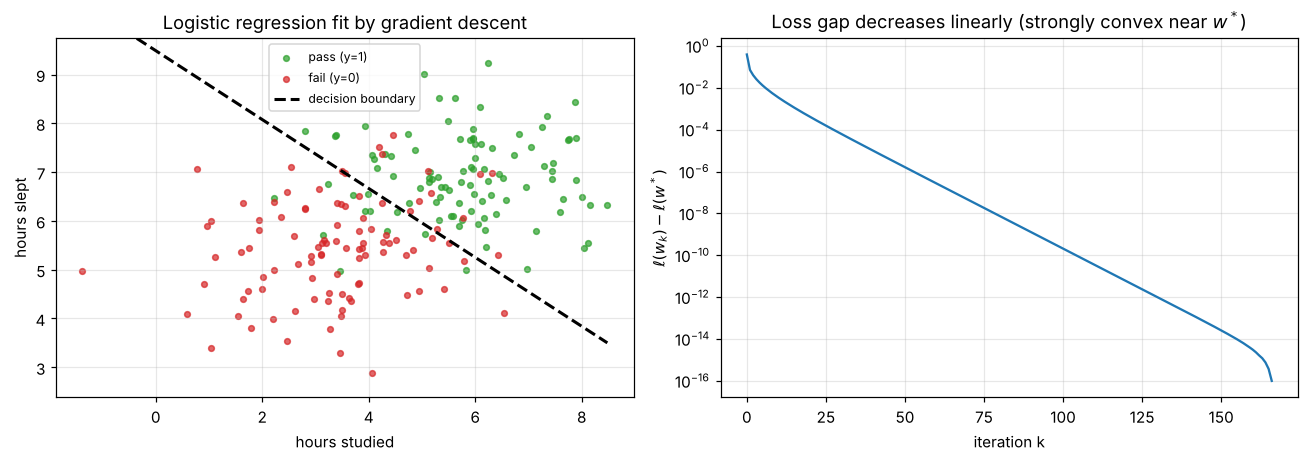

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
axes[0].scatter(*pass_pts.T, s=14, c="tab:green", alpha=0.7, label="pass (y=1)")
axes[0].scatter(*fail_pts.T, s=14, c="tab:red", alpha=0.7, label="fail (y=0)")
# decision boundary w0 + w1*(x1-mu1)/sd1 + w2*(x2-mu2)/sd2 = 0
x1 = np.linspace(feats[:, 0].min(), feats[:, 0].max(), 100)
x2 = mu[1] - sd[1] / w[2] * (w[0] + w[1] * (x1 - mu[0]) / sd[0])
axes[0].plot(x1, x2, "k--", lw=2, label="decision boundary")
axes[0].set_xlabel("hours studied"); axes[0].set_ylabel("hours slept")
axes[0].set_ylim(feats[:, 1].min() - 0.5, feats[:, 1].max() + 0.5)
axes[0].set_title("Logistic regression fit by gradient descent"); axes[0].legend(fontsize=8)

axes[1].semilogy(np.array(hist) - min(hist) + 1e-16)
axes[1].set_xlabel("iteration k"); axes[1].set_ylabel(r"$\ell(w_k)-\ell(w^*)$")
axes[1].set_title("Loss gap decreases linearly (strongly convex near $w^*$)")
plt.tight_layout(); plt.show()

The loss decreased at every step, as the descent lemma guarantees for $\alpha=1/L$. Because the loss is convex, the point where the gradient vanished is the **global** best classifier for this model, not just a local one. The Hessian at $w^*$ is positive definite, so the minimizer is also unique.

---
## Summary

| Concept | What the code showed |
|---|---|
| FONC $\nabla f(x^*)=0$ | Necessary but not sufficient: $x^2(x-2)^2$ has a local max at $x=1$ that also satisfies it. |
| SONC / SOSC | Hessian eigenvalues classify critical points (min, max, saddle); quartic examples show the test can be inconclusive when $\mathbf H$ is singular. |
| Convexity | Chord, tangent and Hessian tests agree; convex vs non-convex sets and functions visualized. |
| Local = global | GD from 31 starts gives one value for a convex function, several for a non-convex one. |
| Least squares | $\mathbf H=2A^TA\succeq0$, normal equations give the global minimizer; no random point does better. |
| Gradient descent | Converges for $0<\alpha<2/L$, diverges beyond; observed rate obeys $(1-1/\kappa)^k$; backtracking handles unknown $L$; scaling improves $\kappa$. |
| My example: logistic regression | Hessian $\succeq0$ (convex), GD with $\alpha=1/L$ decreases the loss every step, and FONC and SOSC hold at the result. |

## Reflection

What surprised me most was how little the first-order condition tells you on its own. In the first example, $x=1$ has a zero derivative but is actually a local maximum, and the quartic examples show that even a zero Hessian can hide a minimum, a maximum or a saddle. Convexity is what removes that uncertainty: for the convex function every gradient descent run ended at the same value, while the non-convex one got stuck in different places depending on where it started. That is why convex losses like least squares and logistic regression are so common in data science, since a zero gradient guarantees the best possible model. The step-size experiments also showed how fragile gradient descent can be in practice: a step just above $2/L$ diverges, and when the condition number grows from 10 to 200 the number of iterations grows by about the same factor. Scaling the features in the least-squares problem lowered the condition number, which is a practical reason to standardize data before training a model.

